# Explainable Machine Learning for Gallstone Disease

## Libraries

In [189]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, validation_curve, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_absolute_error, accuracy_score, f1_score, roc_auc_score, recall_score, precision_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset

In [190]:
gd_df = pd.read_csv("dataset-uci.csv")

## Exploratory Data Analysis (EDA)

In [191]:
gd_df.head(10).T

,0,1,2,3,4,5,6,7,8,9
Gallstone Status,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Age,50.00,47.00,61.00,41.00,42.00,96.00,37.00,41.00,38.00,38.00
Gender,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Comorbidity,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Coronary Artery Disease (CAD),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hypothyroidism,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hyperlipidemia,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Diabetes Mellitus (DM),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Height,185.00,176.00,171.00,168.00,178.00,155.00,185.00,176.00,186.00,171.00
Weight,92.80,94.50,91.10,67.70,89.60,49.00,67.10,114.00,93.70,68.60


In [192]:
gd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                     

In [193]:
gd_df.shape

(319, 39)

In [194]:
gd_df.isnull().sum()

Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)                         0
Bone Mass (B

In [195]:
gd_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.495298,0.500763,0.00,0.000,0.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


In [196]:
gd_df.describe().T.sort_values("std", ascending=False)

,count,mean,std,min,25%,50%,75%,max
Obesity (%),319.0,35.850125,109.799718,0.40,13.900,25.600000,41.750,1954.00
Triglyceride,319.0,144.502163,97.904493,1.39,83.000,119.000000,172.000,838.00
Total Cholesterol (TC),319.0,203.495298,45.758501,60.00,172.000,198.000000,233.000,360.00
Glucose,319.0,108.688715,44.848714,69.00,92.000,98.000000,109.000,575.00
Low Density Lipoprotein (LDL),319.0,126.652351,38.541175,11.00,100.500,122.000000,151.000,293.00
Alanin Aminotransferaz (ALT),319.0,26.855799,27.884413,3.00,14.250,19.000000,30.000,372.00
Alkaline Phosphatase (ALP),319.0,73.112539,24.181069,7.00,58.000,71.000000,86.000,197.00
High Density Lipoprotein (HDL),319.0,49.475549,17.718701,25.00,40.000,46.500000,56.000,273.00
Glomerular Filtration Rate (GFR),319.0,100.818903,16.971396,10.60,94.170,104.000000,110.745,132.00
Aspartat Aminotransferaz (AST),319.0,21.684953,16.697605,8.00,15.000,18.000000,23.000,195.00


In [197]:
gd_df.duplicated().sum()

0

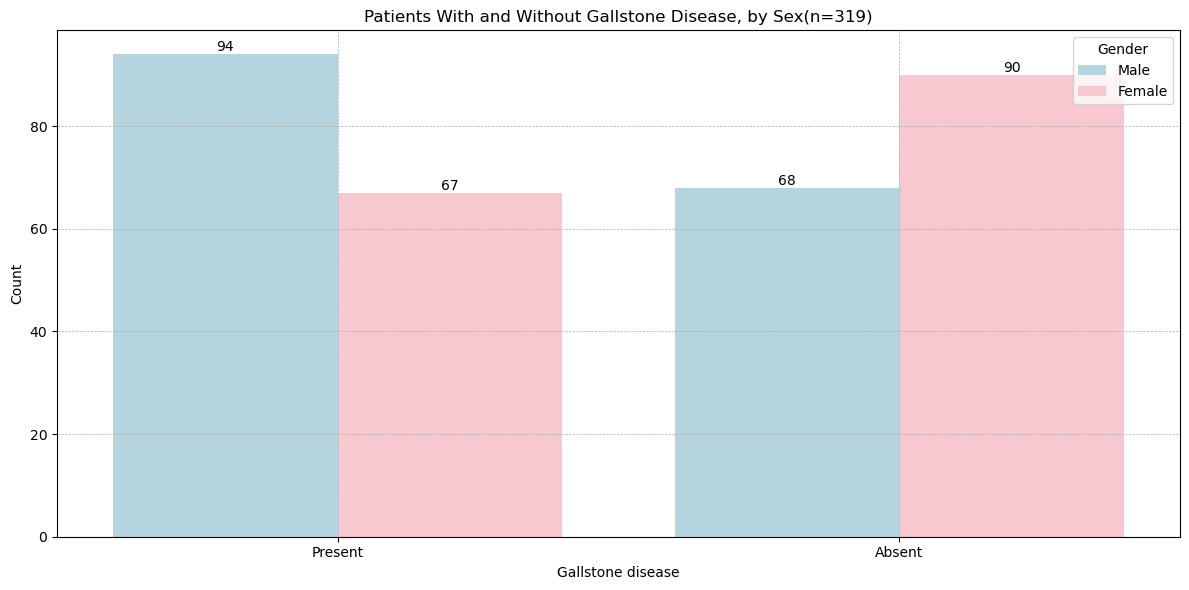

In [198]:
plt.figure(figsize=(12, 6))
plt.title("Patients With and Without Gallstone Disease, by Sex(n=319)")
ax = sns.countplot(x = "Gallstone Status", hue="Gender", data = gd_df, palette= ("lightblue", "pink"))
ax.set_xticklabels(["Present", "Absent"])

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Gallstone disease")
plt.ylabel("Count")
plt.tight_layout()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend(title="Gender", loc="upper right", labels=["Male", "Female"])
plt.show()

After inspecting the dataset statistics (describe()) we noticed obesity had a large standard deviation. This should be taken a closer look at later.

In [199]:
gd_df[["Obesity (%)", "Height", "Weight"]].sort_values("Obesity (%)", ascending=False).head() # anomaly ? 

,Obesity (%),Height,Weight
239,1954.00,150,65.9
23,125.60,170,143.5
209,106.30,150,102.1
280,96.63,150,108.4
246,95.64,162,125.8


In [200]:
gd_df[["Triglyceride", "Height", "Weight"]].sort_values("Triglyceride", ascending=False).head() # anomaly ? 

,Triglyceride,Height,Weight
242,838.0,173,87.8
20,692.0,178,110.7
8,679.0,186,93.7
7,464.0,176,114.0
50,455.0,167,82.2


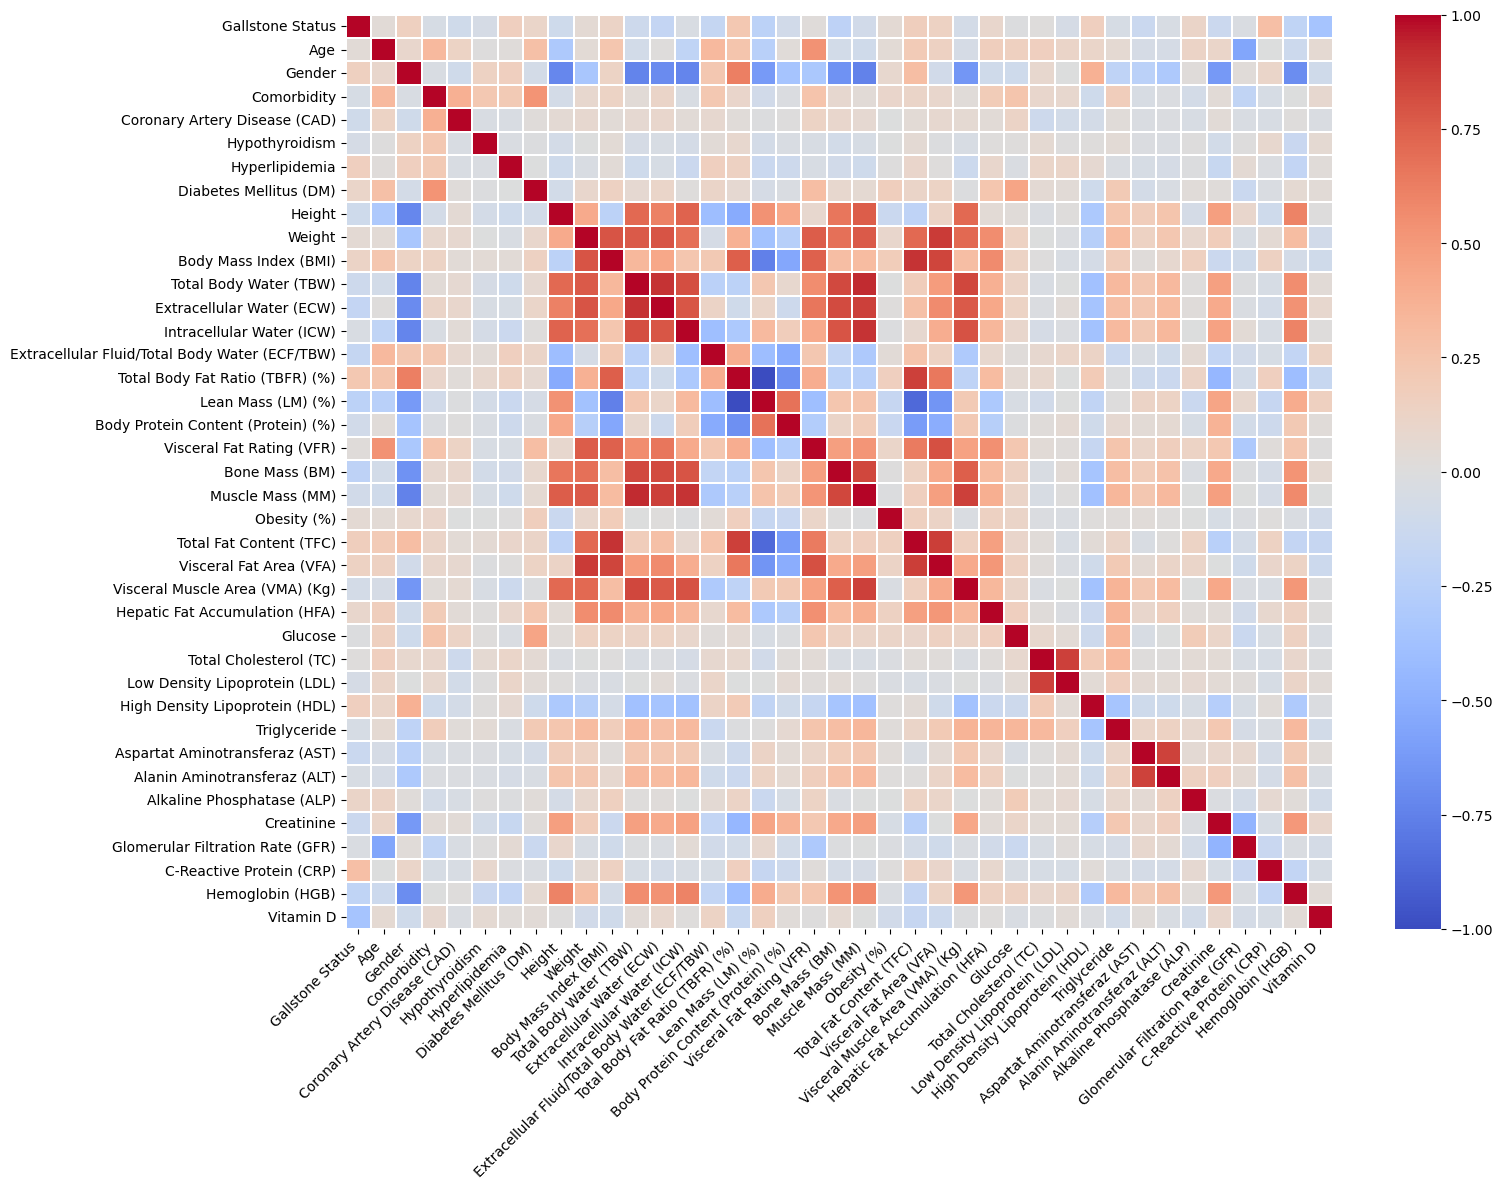

In [201]:
plt.figure(figsize=(16, 12))
sns.heatmap(gd_df.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [202]:
gd_df[["Gallstone Status", "C-Reactive Protein (CRP)"]].sort_values("C-Reactive Protein (CRP)", ascending=False).T

,214,272,231,153,270,268,257,280,277,208,...,124,125,126,127,128,129,130,131,132,318
Gallstone Status,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
C-Reactive Protein (CRP),43.4,36.7,36.1,31.0,24.5,21.4,18.8,16.5,14.0,13.9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [203]:
no_gallstone = gd_df[gd_df["Gallstone Status"] == 1]
no_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,158.0,1.000000,0.000000,1.00,1.000000,1.000000,1.000000,1.00
Age,158.0,48.512658,11.200397,20.00,39.250000,50.000000,56.000000,76.00
Gender,158.0,0.569620,0.496704,0.00,0.000000,1.000000,1.000000,1.00
Comorbidity,158.0,0.310127,0.464016,0.00,0.000000,0.000000,1.000000,1.00
Coronary Artery Disease (CAD),158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hypothyroidism,158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hyperlipidemia,158.0,0.050633,0.219944,0.00,0.000000,0.000000,0.000000,1.00
Diabetes Mellitus (DM),158.0,0.170886,0.377606,0.00,0.000000,0.000000,0.000000,1.00
Height,158.0,166.063291,10.247065,146.00,158.000000,165.000000,174.000000,191.00
Weight,158.0,81.335443,15.444613,42.90,70.225000,79.850000,92.150000,125.80


In [204]:
has_gallstone = gd_df[gd_df["Gallstone Status"] == 0]
has_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Age,161.0,47.633540,12.969527,20.00,38.000,49.00,56.00,96.00
Gender,161.0,0.416149,0.494457,0.00,0.000,0.00,1.00,1.00
Comorbidity,161.0,0.360248,0.565164,0.00,0.000,0.00,1.00,3.00
Coronary Artery Disease (CAD),161.0,0.055901,0.230447,0.00,0.000,0.00,0.00,1.00
Hypothyroidism,161.0,0.037267,0.190007,0.00,0.000,0.00,0.00,1.00
Hyperlipidemia,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Diabetes Mellitus (DM),161.0,0.099379,0.300104,0.00,0.000,0.00,0.00,1.00
Height,161.0,168.229814,9.771929,145.00,162.000,170.00,175.00,188.00
Weight,161.0,79.808696,15.976226,47.30,69.200,78.00,90.50,143.50


In [205]:
gd_df.corrwith(gd_df["Gallstone Status"])

Gallstone Status                                  1.000000
Age                                               0.036339
Gender                                            0.153483
Comorbidity                                      -0.048516
Coronary Artery Disease (CAD)                    -0.096998
Hypothyroidism                                   -0.055196
Hyperlipidemia                                    0.161901
Diabetes Mellitus (DM)                            0.104689
Height                                           -0.107919
Weight                                            0.048669
Body Mass Index (BMI)                             0.121507
Total Body Water (TBW)                           -0.111233
Extracellular Water (ECW)                        -0.178436
Intracellular Water (ICW)                        -0.035274
Extracellular Fluid/Total Body Water (ECF/TBW)   -0.169826
Total Body Fat Ratio (TBFR) (%)                   0.225470
Lean Mass (LM) (%)                               -0.2257

## Separating features and label

In [206]:
X = gd_df.drop(["Gallstone Status"], axis = 1)

# In dataset 0 means a person has Gallstone Disease, while 1 means a person does not have Gallstone Disease
# We prefer it the other way around and therefore change this to 1 = sick, 0 = healthy
y = 1 - gd_df["Gallstone Status"]

## Train/Test Split

In [207]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

print(X_train.shape[0]/319*100)
print(y_train.shape)
print(X_test.shape[0]/319*100, y_test.shape)

79.9373040752351
(255,)
20.06269592476489 (64,)


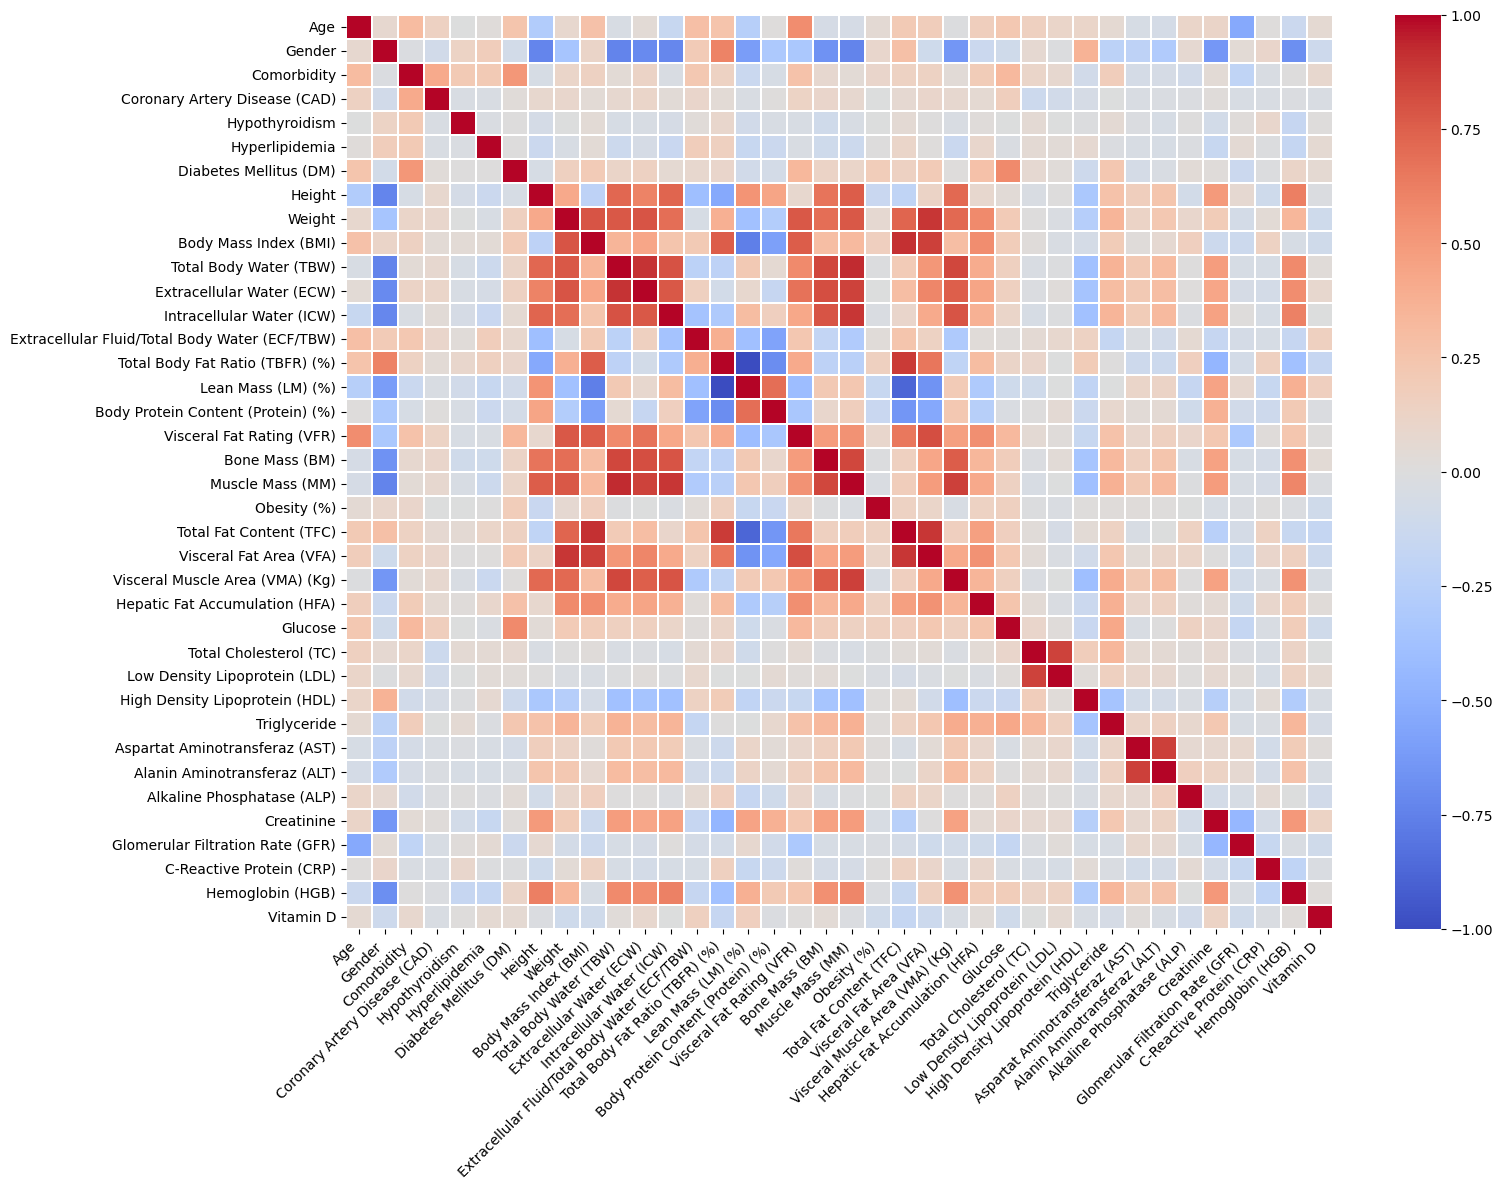

In [208]:
plt.figure(figsize=(16, 12))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [209]:
# correlation values between features
corr = X_train.corr().abs()

corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr = corr[(corr > 0.8) & (corr != 1)].stack()

high_corr.sort_values(ascending=False)

Total Body Fat Ratio (TBFR) (%)  Lean Mass (LM) (%)                 0.998529
Total Body Water (TBW)           Muscle Mass (MM)                   0.926279
Body Mass Index (BMI)            Total Fat Content (TFC)            0.913971
Total Body Water (TBW)           Extracellular Water (ECW)          0.905738
Total Fat Content (TFC)          Visceral Fat Area (VFA)            0.893555
Weight                           Visceral Fat Area (VFA)            0.893361
Intracellular Water (ICW)        Muscle Mass (MM)                   0.891142
Total Body Fat Ratio (TBFR) (%)  Total Fat Content (TFC)            0.877476
Lean Mass (LM) (%)               Total Fat Content (TFC)            0.876631
Body Mass Index (BMI)            Visceral Fat Area (VFA)            0.862793
Aspartat Aminotransferaz (AST)   Alanin Aminotransferaz (ALT)       0.861874
Muscle Mass (MM)                 Visceral Muscle Area (VMA) (Kg)    0.860822
Total Cholesterol (TC)           Low Density Lipoprotein (LDL)      0.856290

In [210]:
X_train[["Total Body Fat Ratio (TBFR) (%)", "Lean Mass (LM) (%)"]].corr()

,Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%)
Total Body Fat Ratio (TBFR) (%),1.000000,-0.998529
Lean Mass (LM) (%),-0.998529,1.000000


In [211]:
mutual_info = mutual_info_classif(X_train, y_train, random_state=1)
mutual_info = pd.Series(mutual_info, index = X_train.columns).sort_values(ascending=False)
mutual_info

C-Reactive Protein (CRP)                          0.248342
Extracellular Fluid/Total Body Water (ECF/TBW)    0.119259
Extracellular Water (ECW)                         0.092971
Intracellular Water (ICW)                         0.092498
Alkaline Phosphatase (ALP)                        0.061467
Vitamin D                                         0.058547
Triglyceride                                      0.051534
Muscle Mass (MM)                                  0.048321
Visceral Fat Area (VFA)                           0.046145
Gender                                            0.045462
Total Cholesterol (TC)                            0.045391
High Density Lipoprotein (HDL)                    0.042819
Body Protein Content (Protein) (%)                0.039445
Hepatic Fat Accumulation (HFA)                    0.036767
Aspartat Aminotransferaz (AST)                    0.019159
Age                                               0.013122
Diabetes Mellitus (DM)                            0.0129

In [212]:
drop_features = ["Total Body Water (TBW)", "Lean Mass (LM) (%)", "Obesity (%)"] # justification in feature_selection.md

X_train_selected = X_train.drop(columns=drop_features)
X_test_selected = X_test.drop(columns=drop_features)

# now only 35 features
print(X_train_selected.shape)
print(X_test_selected.shape)

(255, 35)
(64, 35)


Til neste gang: må velge meassurement typer (accuracy, precision, recall, f1, roc-auc). Deretter kjøre Cross-validation. 

Using sklearns pipeline

In [213]:
models = {
"Logistic Regression" : Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
]),

"Random Forest" : Pipeline([
    ("model", RandomForestClassifier())
]),

"Gradient Boost" : Pipeline([
    ("model", GradientBoostingClassifier())
]), 

"SVM" : Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())]),

"KNN" : Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])
}

In [214]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

In [215]:
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

In [216]:
results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train_selected,
        y_train,
        cv=cross_validation,
        scoring=scoring
    )

    results[name] = scores

In [217]:
results_all = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cross_validation,
        scoring=scoring
    )

    results_all[name] = scores

### Results of 5-fold with 35 features

In [218]:
comparison = pd.DataFrame()

for name, scores in results.items():
    for metric in scoring:
        mean = scores[f"test_{metric}"].mean()
        sd = scores[f"test_{metric}"].std()

        comparison.loc[name, metric] = f"{mean: .3f} ± {sd: .3f}"

display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.784 ± 0.071,0.766 ± 0.065,0.829 ± 0.087,0.795 ± 0.068,0.848 ± 0.071
Random Forest,0.776 ± 0.047,0.761 ± 0.047,0.814 ± 0.058,0.786 ± 0.049,0.840 ± 0.041
Gradient Boost,0.729 ± 0.052,0.719 ± 0.043,0.759 ± 0.069,0.738 ± 0.055,0.802 ± 0.060
SVM,0.725 ± 0.055,0.694 ± 0.049,0.822 ± 0.089,0.751 ± 0.054,0.802 ± 0.038
KNN,0.631 ± 0.038,0.604 ± 0.032,0.791 ± 0.057,0.684 ± 0.034,0.688 ± 0.050


### Results of 5-fold with 38 features

In [219]:
comparison = pd.DataFrame()

for name, scores in results_all.items():
    for metric in scoring:
        mean = scores[f"test_{metric}"].mean()
        sd = scores[f"test_{metric}"].std()

        comparison.loc[name, metric] = f"{mean: .3f} ± {sd: .3f}"

display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.780 ± 0.069,0.761 ± 0.065,0.829 ± 0.087,0.792 ± 0.066,0.843 ± 0.061
Random Forest,0.753 ± 0.059,0.739 ± 0.057,0.790 ± 0.075,0.763 ± 0.062,0.820 ± 0.056
Gradient Boost,0.745 ± 0.041,0.739 ± 0.029,0.767 ± 0.090,0.750 ± 0.050,0.804 ± 0.056
SVM,0.729 ± 0.040,0.698 ± 0.033,0.822 ± 0.067,0.754 ± 0.039,0.804 ± 0.036
KNN,0.643 ± 0.064,0.610 ± 0.046,0.814 ± 0.089,0.696 ± 0.060,0.697 ± 0.071


## Testing GridsearchCV

In [228]:
param_grid = {
    "model__C" : [0.01, 0.1, 1, 10, 100, 200]
}

grid_search = GridSearchCV(estimator=models["Logistic Regression"],
                           param_grid=param_grid,
                           cv=cross_validation,
                           scoring="roc_auc",
                           return_train_score=True)

grid_search.fit(X_train_selected, y_train)


print("Best parameters: ", grid_search.best_params_)
print("Best score: ", grid_search.best_score_)

Best parameters:  {'model__C': 100}
Best score:  0.8526153846153847


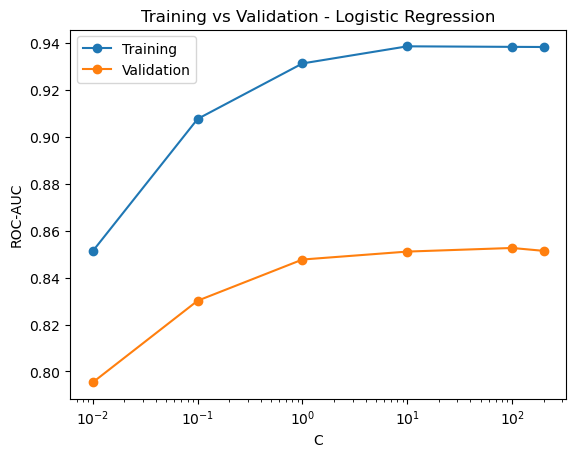

In [229]:
results = pd.DataFrame(grid_search.cv_results_)

plt.plot(
    results["param_model__C"].astype(float),
    results["mean_train_score"],
    marker="o",
    label="Training"
)

plt.plot(
    results["param_model__C"].astype(float),
    results["mean_test_score"],
    marker="o",
    label="Validation"
)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation - Logistic Regression")
plt.legend()
plt.show()

For Logistic regression we decided to tune the C parameter from the standard C=1 to C=10. This was done even though C=100 achieved a better score than the others. Our reasoning for this choice was mainly due to there being a microscopical difference between the results of C=10 and C=100, and the fact that we wanted to keep more of the regularization.  

## Now we fit

In [221]:
model = models["Logistic Regression"]
model.fit(X_train, y_train)
# make predictions
y_pred = model.predict(X_test)

In [222]:
print('Accuracy score: %.3f' % accuracy_score(y_test, y_pred))
print('F1-score: %.3f' % f1_score(y_test, y_pred))
print('Recall score: %.3f' % recall_score(y_test, y_pred))
print('Precision score: %.3f' % precision_score(y_test, y_pred))
print('ROC-AUC score: %.3f' % roc_auc_score(y_test, y_pred))

Accuracy score: 0.766
F1-score: 0.769
Recall score: 0.781
Precision score: 0.758
ROC-AUC score: 0.766


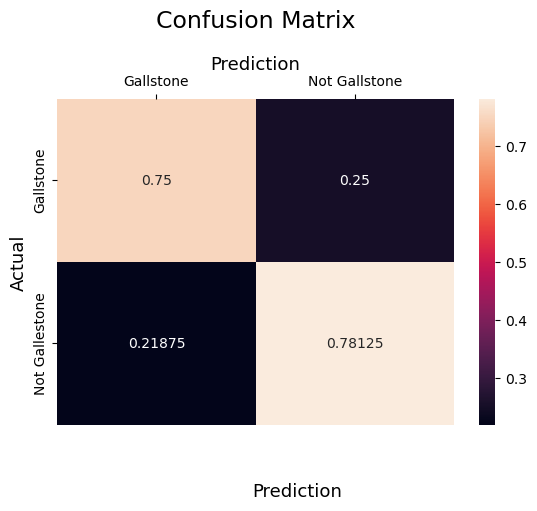

              precision    recall  f1-score   support

           0       0.77      0.75      0.76        32
           1       0.76      0.78      0.77        32

    accuracy                           0.77        64
   macro avg       0.77      0.77      0.77        64
weighted avg       0.77      0.77      0.77        64



In [223]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(cm, 
            annot=True,
            fmt='g', 
            xticklabels=['Gallstone','Not Gallstone'],
            yticklabels=['Gallstone','Not Gallestone'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top') 
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()
print(classification_report(y_test, y_pred))

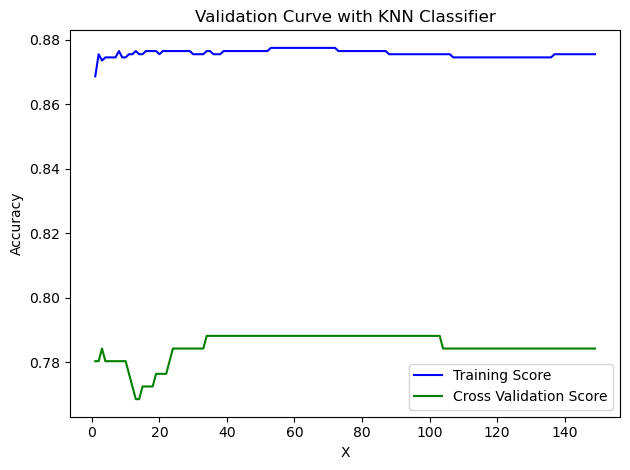

In [224]:
parameter_range = np.arange(1, 150, 1)
train_score, test_score = validation_curve(estimator=models["Logistic Regression"], X=X_train, y=y_train,
                 param_name="model__C", param_range=parameter_range,
                                           cv=cross_validation, scoring="accuracy")

# Calculating mean and standard deviation of training score
mean_train_score = np.mean(train_score, axis=1)
std_train_score = np.std(train_score, axis=1)

# Calculating mean and standard deviation of testing score
mean_test_score = np.mean(test_score, axis=1)
std_test_score = np.std(test_score, axis=1)

# Plot mean accuracy scores for training and testing scores
plt.plot(parameter_range, mean_train_score,
         label="Training Score", color='b')
plt.plot(parameter_range, mean_test_score,
         label="Cross Validation Score", color='g')

# Creating the plot
plt.title("Validation Curve with KNN Classifier")
plt.xlabel("X")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.legend(loc='best')
plt.show()

# Husk feature importance